# 04 - Class weights and ensembles of networks
Wine Quality dataset (red and white wines)

Two ideas to improve the network of notebook 01:

1. **Weighted cross-entropy.** In notebook 01 the recall of the High class was only 0.39, because
   High is the smallest class (19% of the wines). With class weights, an error on a High wine costs
   more than an error on a Medium wine. The weight of class $k$ is $N / (K \cdot N_k)$, computed
   with the training part of each fold (the same as `class_weight="balanced"` in scikit-learn).
2. **Ensemble.** We train 5 networks that are identical except for the random seed (different
   initial weights and different order of the mini-batches) and average their predictions (the
   scores for regression and the probabilities for classification). This is the same idea as the
   random forest, which averages many trees.

All the networks use the architecture chosen most often in notebook 01 for each task
(64-32 for regression and 128-64-32 for classification) and the same 5 outer folds.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, r2_score, f1_score, accuracy_score,
                             recall_score, confusion_matrix)

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

mse = nn.MSELoss()
def reg_loss(out, yb):
    return mse(out.squeeze(1), yb)

In [2]:
wine = load_wine()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy().astype(float)
c = wine["class_id"].to_numpy()
SEEDS = [0, 1, 2, 3, 4]
REG_HIDDEN, CLF_HIDDEN, DROPOUT = (64, 32), (128, 64, 32), 0.1

## 1. Regression: single network vs ensemble

In [3]:
outer_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_rows = []
for fold, (train_idx, test_idx) in enumerate(outer_reg.split(X), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED)
    scaler = StandardScaler().fit(X[tr])
    y_mean, y_std = y[tr].mean(), y[tr].std()
    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))

    preds = []
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = MLP(X.shape[1], REG_HIDDEN, 1, DROPOUT)
        train_model(model, Xtr, (ytr,), Xval, (yval,), reg_loss, seed=seed)
        with torch.no_grad():
            preds.append(model.eval()(Xte).squeeze(1).numpy() * y_std + y_mean)
    singles = [rmse(y[test_idx], p) for p in preds]
    reg_rows.append({"fold": fold, "Single network (mean of 5)": np.mean(singles),
                     "Ensemble of 5 networks": rmse(y[test_idx], np.mean(preds, axis=0))})
    print(reg_rows[-1])

reg_res = pd.DataFrame(reg_rows)
reg_res.to_csv(RES_DIR / "ensemble_regression_folds.csv", index=False)
reg_res.drop(columns="fold").agg(["mean", "std"]).round(3)

{'fold': 1, 'Single network (mean of 5)': np.float64(0.6768880110670257), 'Ensemble of 5 networks': np.float64(0.6726926506359461)}


{'fold': 2, 'Single network (mean of 5)': np.float64(0.6806952815414073), 'Ensemble of 5 networks': np.float64(0.6767608629710323)}


{'fold': 3, 'Single network (mean of 5)': np.float64(0.6896826008543547), 'Ensemble of 5 networks': np.float64(0.6854908385629286)}


{'fold': 4, 'Single network (mean of 5)': np.float64(0.710556882984412), 'Ensemble of 5 networks': np.float64(0.7066402826826644)}


{'fold': 5, 'Single network (mean of 5)': np.float64(0.7146958769883289), 'Ensemble of 5 networks': np.float64(0.7105587731526936)}


,Single network (mean of 5),Ensemble of 5 networks
mean,0.695,0.690
std,0.017,0.017


## 2. Classification: class weights and ensemble

In [4]:
outer_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CONFIGS = ["Single network", "Single network, class weights", "Ensemble of 5, class weights"]
clf_rows = []
oof = {name: np.zeros(len(c), dtype=int) for name in CONFIGS}

for fold, (train_idx, test_idx) in enumerate(outer_clf.split(X, c), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED, stratify=c[train_idx])
    scaler = StandardScaler().fit(X[tr])
    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ctr, cval = (torch.tensor(c[i], dtype=torch.long) for i in (tr, val))

    counts = np.bincount(c[tr], minlength=3)
    weights = torch.tensor(len(tr) / (3 * counts), dtype=torch.float32)
    ce_plain, ce_weighted = nn.CrossEntropyLoss(), nn.CrossEntropyLoss(weight=weights)

    probs = {"plain": [], "weighted": []}
    for seed in SEEDS:
        for kind, ce in [("plain", ce_plain), ("weighted", ce_weighted)]:
            if kind == "plain" and seed != SEEDS[0]:
                continue
            torch.manual_seed(seed)
            model = MLP(X.shape[1], CLF_HIDDEN, 3, DROPOUT)
            train_model(model, Xtr, (ctr,), Xval, (cval,), lambda out, yb, ce=ce: ce(out, yb), seed=seed)
            with torch.no_grad():
                probs[kind].append(torch.softmax(model.eval()(Xte), dim=1).numpy())

    preds = {"Single network": probs["plain"][0].argmax(1),
             "Single network, class weights": probs["weighted"][0].argmax(1),
             "Ensemble of 5, class weights": np.mean(probs["weighted"], axis=0).argmax(1)}
    for name, p in preds.items():
        oof[name][test_idx] = p
        rec = recall_score(c[test_idx], p, average=None)
        clf_rows.append({"fold": fold, "model": name, "Macro F1": f1_score(c[test_idx], p, average="macro"),
                         "Accuracy": accuracy_score(c[test_idx], p),
                         "Recall Low": rec[0], "Recall Medium": rec[1], "Recall High": rec[2]})
    print(f"fold {fold} done")

clf_res = pd.DataFrame(clf_rows)
clf_res.to_csv(RES_DIR / "class_weights_ensemble_folds.csv", index=False)
clf_summary = clf_res.groupby("model", sort=False).mean(numeric_only=True).drop(columns="fold")
clf_summary["Macro F1 std"] = clf_res.groupby("model", sort=False)["Macro F1"].std()
clf_summary.to_csv(RES_DIR / "class_weights_ensemble_summary.csv")
clf_summary.round(3)

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


,Macro F1,Accuracy,Recall Low,Recall Medium,Recall High,Macro F1 std
model,,,,,,
Single network,0.592,0.607,0.677,0.608,0.470,0.007
"Single network, class weights",0.564,0.566,0.683,0.379,0.765,0.014
"Ensemble of 5, class weights",0.565,0.570,0.714,0.365,0.757,0.007


## 3. Recall per class

Figure saved -> ../results/figures/class_weights_ensemble.png


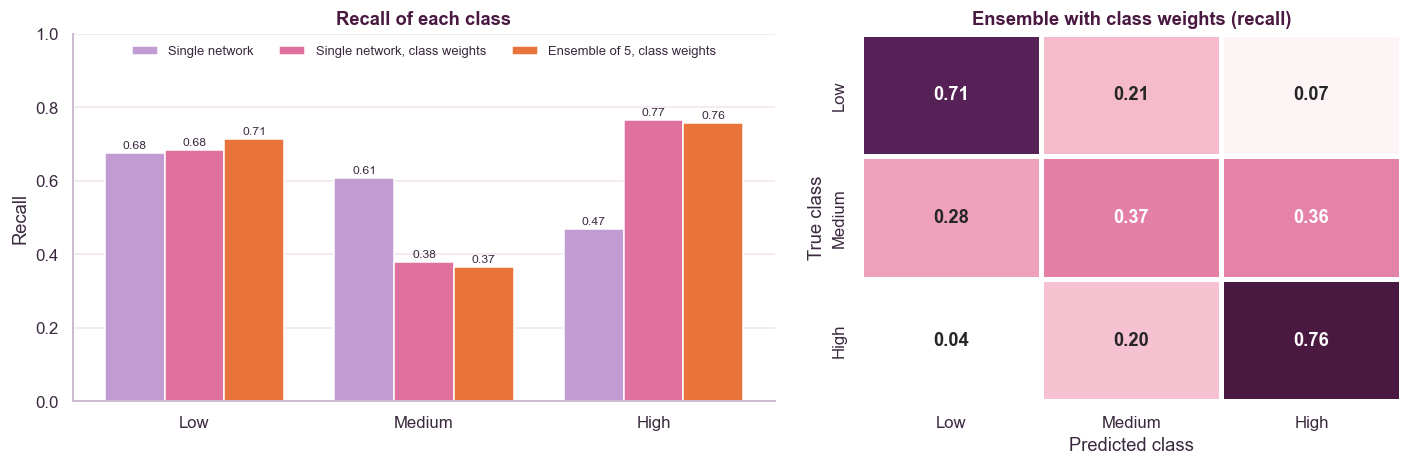

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
width = 0.26
pos = np.arange(3)
for i, (name, col) in enumerate(zip(CONFIGS, [LILAC, PINK, ORANGE])):
    vals = clf_summary.loc[name, ["Recall Low", "Recall Medium", "Recall High"]].to_numpy()
    ax.bar(pos + (i - 1) * width, vals, width, color=col, label=name, edgecolor="white")
    for p, v in zip(pos + (i - 1) * width, vals):
        ax.text(p, v + 0.012, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(pos)
ax.set_xticklabels(CLASS_ORDER)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Recall")
ax.set_title("Recall of each class")
ax.legend(fontsize=8.5, loc="upper center", ncol=3, frameon=False)
ax.grid(axis="x", visible=False)

cm = confusion_matrix(c, oof["Ensemble of 5, class weights"])
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap=CMAP_SEQ, cbar=False,
            linewidths=2, linecolor="white", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
            ax=axes[1], annot_kws={"weight": "bold"})
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
axes[1].set_title("Ensemble with class weights (recall)")
fig.tight_layout()
save(fig, "class_weights_ensemble.png")
plt.show()

## Summary

* Class weights move predictions from Medium to High: the recall of the High class goes up from
  0.47 to 0.77, but the recall of Medium goes down from 0.61 to 0.38. Since Medium is the biggest
  class, the accuracy (0.61 to 0.57) and the macro F1 (0.592 to 0.564) go down. Class weights are
  useful if finding the good wines matters more than the overall accuracy, but they do not give a
  better model in general.
* For regression, the ensemble of 5 networks is better than a single network in all 5 folds
  (RMSE 0.690 vs 0.695). The improvement is small but consistent: averaging several networks
  reduces the variance, in the same way as the random forest does with trees.
* For classification (with class weights), the ensemble gives almost the same macro F1 as a single
  network (0.565 vs 0.564), but with half the standard deviation between folds (0.007 vs 0.014).